# 05 · Placar das três configurações, alucinações e os 5 erros

Cobre os itens **06** (placar das três configurações, com resultados interpretados) e **07** (5 erros reais com proposta de correção).

Este notebook **não chama a LLM**: lê as respostas gravadas em `avaliacao/resultados/` por `scripts/avaliar.py`. Cada resposta está lá inteira, com as fontes citadas, o motivo da decisão e, no agente, os passos.

**Como o placar é calculado** (`avaliacao.julgar`):

* **correta**: a resposta contém todos os pontos-chave do gabarito;
* **parcial**: contém parte dos pontos;
* **incorreta**: não contém os pontos, ou contém um erro marcado como proibido (por exemplo, telefone de emergência trocado);
* **recusa correta**: recusou uma pergunta que não consta na base;
* **recusa indevida**: recusou uma pergunta que a base (ou o mapa) responde;
* **alucinação**: respondeu uma pergunta que não consta.

**Acerto** = corretas + recusas corretas. **Alucinação** (no placar) = incorretas + alucinações, isto é, toda resposta errada que chegou ao morador. Parciais e recusas indevidas não entram em nenhuma das duas.

O juiz é automático e foi auditado: as respostas foram lidas uma a uma e os padrões que julgavam mal foram corrigidos, sempre valendo para as três configurações (`avaliacao/AUDITORIA.md`).

In [1]:
import os, sys, json
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src")); sys.path.insert(0, str(RAIZ / "scripts"))
os.environ["MAPA_URL"] = ""
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 220); pd.set_option("display.width", 240)
from boca_de_lobo_ia import avaliacao, config

casos = {c["id"]: c for c in avaliacao.carregar_casos()}
res = {nome: avaliacao.carregar_resultados(nome) for nome in avaliacao.CONFIGURACOES}
print({nome: len(r) for nome, r in res.items()}, "| modelo:", config.MODELO_LLM, "| limiar:", config.limiar_recusa())

def registro(cid, nome):
    """Mostra uma resposta gravada, com o que explica a decisão."""
    c, r = casos[cid], res[nome][cid]
    print(f"[{cid}] {avaliacao.ROTULOS[nome]} -> {r['julgamento']['veredito']}  ({r['chamadas_llm']} chamada(s) à LLM)")
    print("pergunta :", c["pergunta"])
    print("esperado :", c["resposta_esperada"])
    print("resposta :", r["resposta"])
    print("fontes   :", [f.get("id") or f.get("descricao") for f in r["fontes"]])
    print("motivo   :", r["motivo"], "| confiança:", r.get("confianca"), "| limiar:", r.get("limiar"))
    if r.get("analise"): print("análise  :", r["analise"])
    if r.get("recuperados"): print("busca    :", list(dict.fromkeys(x["id"] for x in r["recuperados"]))[:8])
    for p in r.get("passos", []):
        if p["passo"] in ("planejar", "consultar_mapa", "verificar", "recusar"): print("   passo :", json.dumps(p, ensure_ascii=False)[:200])
    print()

def lado_a_lado(ids):
    linhas = []
    for cid in ids:
        linha = {"id": cid, "pergunta": casos[cid]["pergunta"], "esperado": casos[cid]["resposta_esperada"][:110]}
        for nome in avaliacao.CONFIGURACOES:
            r = res[nome][cid]
            linha[avaliacao.ROTULOS[nome]] = f"[{r['julgamento']['veredito']}] {r['resposta'][:230]}"
        linhas.append(linha)
    return pd.DataFrame(linhas)

{'sem_contexto': 77, 'rag': 77, 'agente': 77} | modelo: gemma3:4b | limiar: 0.55


## Placar na partição de teste (56 casos)

As três configurações usam **o mesmo modelo** (`gemma3:4b`), a mesma temperatura (0) e a mesma semente:

1. **LLM sem contexto**: o modelo responde de memória;
2. **RAG simples**: busca híbrida, limiar e geração presa a 3 trechos;
3. **Agente**: planeja consultas, usa as ferramentas (busca e mapa), verifica e tem uma segunda rodada.

In [2]:
import gerar_placar
colunas = dict(gerar_placar.COLUNAS)
placar = pd.DataFrame(avaliacao.placar("teste"))
placar[list(colunas)].rename(columns=colunas).set_index("Configuração")

,Casos,Acerto (%),Alucinação (%),Recusa indevida (%),"Recusa no ""não consta"" (%)",Citação correta (%),JSON válido (%),Chamadas à LLM
Configuração,,,,,,,,
1. LLM sem contexto,56,30.4,60.7,4.5,33.3,0.0,100.0,1.00
2. RAG simples,56,76.8,5.4,22.7,100.0,90.6,100.0,0.71
3. Agente (especialização),56,85.7,7.1,6.8,91.7,85.0,100.0,1.82


In [3]:
vereditos = pd.DataFrame([{"configuração": avaliacao.ROTULOS[n], "veredito": r["julgamento"]["veredito"]}
                          for n in avaliacao.CONFIGURACOES for r in res[n].values() if r["particao"] == "teste"])
tab = pd.crosstab(vereditos["configuração"], vereditos["veredito"]).reindex(columns=avaliacao.VEREDITOS, fill_value=0)
tab

veredito,correta,parcial,incorreta,recusa_correta,recusa_indevida,alucinacao
configuração,,,,,,
1. LLM sem contexto,11,3,26,6,2,8
2. RAG simples,29,0,3,14,10,0
3. Agente (especialização),36,1,3,12,3,1


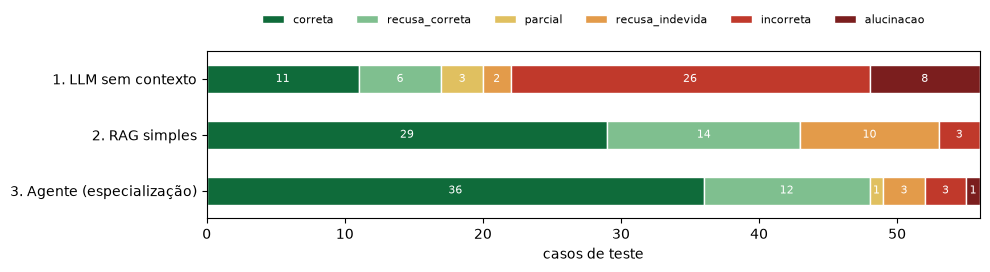

In [4]:
cores = {"correta": "#0f6b3a", "recusa_correta": "#7fbf8f", "parcial": "#e0c060", "recusa_indevida": "#e39b4a", "incorreta": "#c0392b", "alucinacao": "#7b1e1e"}
ordem = ["correta", "recusa_correta", "parcial", "recusa_indevida", "incorreta", "alucinacao"]
ax = tab[ordem].plot.barh(stacked=True, figsize=(10, 3), color=[cores[o] for o in ordem], edgecolor="white")
ax.set_xlabel("casos de teste"); ax.set_ylabel(""); ax.invert_yaxis()
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.28), fontsize=8, frameon=False)
for c in ax.containers:
    ax.bar_label(c, labels=[int(v) if v else "" for v in c.datavalues], label_type="center", fontsize=8, color="white")
plt.tight_layout(); plt.show()

### Leitura

**O objetivo do enunciado foi atingido: com a base, o mesmo modelo acerta mais e alucina menos.**

* **Sem contexto**, o `gemma3:4b` acerta 17 das 56 perguntas (30,4%) e entrega uma resposta errada ou inventada em 34 (60,7%). Ele quase nunca diz "não sei": das 12 perguntas que não constam, recusou 4.
* **RAG simples**: 43 acertos (76,8%) e 3 respostas erradas (5,4%). Recusou as 12 perguntas que não constam. O preço é a cautela: 10 recusas indevidas, das quais 5 são perguntas sobre bairros (que ele não tem como responder), 3 foram barradas pelo limiar e 2 por falha da busca.
* **Agente**: 48 acertos (85,7%) e 4 respostas erradas (7,1%). Em relação ao RAG simples, ganhou 6 perguntas (4 respondidas com o mapa e 2 em que a consulta planejada trouxe o trecho que faltava) e perdeu 1 (respondeu uma pergunta que não consta).

Do modelo sem contexto para o RAG, a alucinação cai de 60,7% para 5,4% (11 vezes menos) e o acerto sobe 46 pontos. Do RAG para o agente, o acerto sobe mais 9 pontos e a alucinação sobe 1,7 ponto (uma resposta a mais).

**JSON válido** ficou em 100% nas três, porque a decodificação restrita do Ollama impede saída fora do formato. **Citação correta**: 90,6% no RAG e 85,0% no agente (o modelo sem contexto não tem como citar trecho). Quando a citação não bate com o gabarito, em geral a resposta veio de um trecho vizinho que diz a mesma coisa.

Com 56 casos, cada caso vale 1,8 ponto percentual. A diferença entre o modelo sem contexto e os outros dois é grande demais para ser acaso. A diferença entre RAG e agente (5 casos de acerto, 1 de erro) é pequena e deve ser lida como tendência.

## Por categoria de pergunta

In [5]:
cat = pd.DataFrame(avaliacao.placar_por_categoria("teste"))
acerto = cat.pivot(index="categoria", columns="configuracao", values="acerto_pct")
aluc = cat.pivot(index="categoria", columns="configuracao", values="alucinacao_pct")
n = cat.drop_duplicates("categoria").set_index("categoria")["casos"]
pd.concat({"casos": n.to_frame("n"), "acerto (%)": acerto, "alucinação (%)": aluc}, axis=1)

casos          acerto (%)                                                alucinação (%)                                          
                     n 1. LLM sem contexto 2. RAG simples 3. Agente (especialização) 1. LLM sem contexto 2. RAG simples 3. Agente (especialização)
categoria                                                                                                                                         
alertas_servicos     7                14.3           71.4                       85.7                71.4           14.3                       14.3
direitos            12                16.7           91.7                       91.7                75.0            8.3                        8.3
multi                5                20.0           80.0                       80.0                40.0           20.0                        0.0
nao_consta          12                33.3          100.0                       91.7                66.7            0.0                        8.3
orientacao          14                57.1           71.4                       78.6                42.9            0.0                        0.0
produto              5                 0.0            0.0                       80.0                80.0            0.0                       20.0
seguranca            1               100.0          100.0                      100.0                 0.0            0.0                        0.0

### Leitura por categoria

* **Direitos** (FGTS, IPTU, Cartão Emergencial) é onde o modelo sem contexto mais erra: 2 acertos em 12, com valores, prazos e regras inventados. São perguntas de número exato, e número exato a LLM não sabe de memória. Com a base, RAG e agente acertam 11 de 12.
* **Orientação** (o que fazer) é onde o modelo sem contexto vai melhor (8 de 14), porque boa parte é senso comum. Mesmo assim erra em 6, e alguns erros são perigosos (ver a seção de alucinações).
* **Não consta**: o RAG recusa as 12; o agente, 11; o modelo sem contexto, 4.
* **Produto** (situação de um bairro): só o agente responde, porque só ele consulta o mapa. Acertou 4 de 5 e errou 1 lendo mal o dado.
* **Multi** (dois assuntos): RAG e agente acertam 4 de 5. No caso restante, o RAG inventou um telefone e o agente respondeu sem o telefone (parcial).
* **Segurança** (instrução maliciosa na pergunta): as três configurações não obedeceram.

In [6]:
sem_produto = pd.DataFrame(avaliacao.placar("teste", excluir_categorias=("produto",)))
sem_produto[list(colunas)].rename(columns=colunas).set_index("Configuração")

,Casos,Acerto (%),Alucinação (%),Recusa indevida (%),"Recusa no ""não consta"" (%)",Citação correta (%),JSON válido (%),Chamadas à LLM
Configuração,,,,,,,,
1. LLM sem contexto,51,33.3,58.8,2.6,33.3,0.0,100.0,1.00
2. RAG simples,51,84.3,5.9,12.8,100.0,90.6,100.0,0.78
3. Agente (especialização),51,86.3,5.9,7.7,91.7,82.9,100.0,1.80


### Sem as perguntas de produto

Tirando as 5 perguntas que dependem do mapa, a comparação fica restrita ao que os dois podem responder: o agente acerta 44 de 51 (86,3%) e o RAG simples, 43 de 51 (84,3%), com a mesma taxa de erro entregue (5,9%, 3 casos cada).

Ou seja: **o ganho do agente vem quase todo da ferramenta do mapa.** Nas perguntas respondidas só com documentos, o planejamento rendeu um acerto a mais (duas perguntas recuperadas e uma resposta indevida), ao custo de mais que o dobro de chamadas à LLM.

## Custo: tempo de resposta e chamadas à LLM

In [7]:
linhas_tempo, dados_tempo = gerar_placar.tempos()
print("máquina:", dados_tempo["maquina"], "| modelo:", dados_tempo["modelo"], "| perguntas:", dados_tempo["amostra"])
pd.DataFrame(linhas_tempo).rename(columns=dict(gerar_placar.COLUNAS_TEMPO)).set_index("Configuração")

máquina: AMD Ryzen 5 5600X, 6 núcleos, 32 GB de RAM (CPU, sem GPU; Ollama em container Docker) | modelo: gemma3:4b | perguntas: ['S01', 'S03', 'S06', 'S10', 'S18', 'S21', 'D01', 'D06', 'D12', 'M01', 'N01', 'N05']


,Perguntas,Tempo mediano (s),Tempo médio (s),Percentil 90 (s),Máximo (s),Chamadas à LLM
Configuração,,,,,,
1. LLM sem contexto,12,12.6,13.4,15.3,18.2,1
2. RAG simples,12,27.1,26.0,29.7,29.9,1
3. Agente (especialização),12,36.3,36.8,42.6,46.0,2


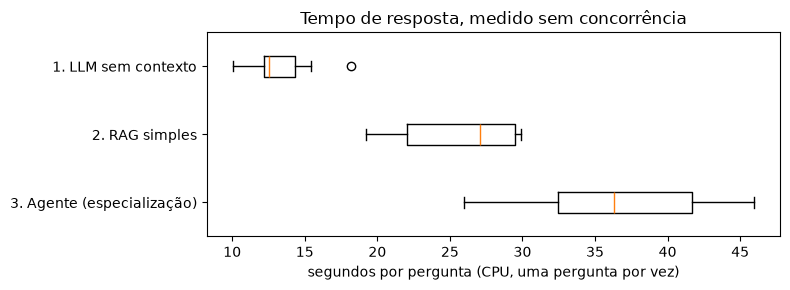

In [8]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.boxplot([dados_tempo["configuracoes"][n]["tempos_s"] for n in avaliacao.CONFIGURACOES], orientation="horizontal",
           tick_labels=[avaliacao.ROTULOS[n] for n in avaliacao.CONFIGURACOES])
ax.set_xlabel("segundos por pergunta (CPU, uma pergunta por vez)"); ax.invert_yaxis()
ax.set_title("Tempo de resposta, medido sem concorrência")
plt.tight_layout(); plt.show()

In [9]:
# Chamadas à LLM por pergunta na partição de teste (não dependem da máquina)
chamadas = pd.DataFrame([{"configuração": avaliacao.ROTULOS[n], "chamadas": r["chamadas_llm"]}
                         for n in avaliacao.CONFIGURACOES for r in res[n].values() if r["particao"] == "teste"])
pd.crosstab(chamadas["configuração"], chamadas["chamadas"])

chamadas,0,1,2
configuração,,,
1. LLM sem contexto,0,56,0
2. RAG simples,16,40,0
3. Agente (especialização),0,10,46


### Leitura

O tempo foi medido à parte (`scripts/medir_tempos.py`, 12 perguntas da partição dev, uma por vez), porque parte das rodadas de avaliação foi feita com dois processos disputando o processador e os tempos gravados em `avaliacao/resultados/` não são comparáveis.

* O RAG simples custa uma chamada à LLM por pergunta respondida e **nenhuma** quando o limiar recusa (resposta em menos de um segundo).
* O agente custa duas chamadas (planejar e responder) e uma terceira quando precisa refazer. Na partição de teste nenhuma resposta do agente precisou da terceira chamada.
* Tudo isso é em CPU, com um modelo de 4 bilhões de parâmetros. É lento para uma conversa, e é a principal limitação do protótipo (não medimos em GPU, onde a geração costuma ser muito mais rápida). A tela mantém os telefones 199 e 193 visíveis enquanto a resposta é gerada.

## Demonstração de alucinações

Seis perguntas de teste, lado a lado. A primeira coluna de resposta é o modelo **sem contexto**: o texto é fluente, confiante e errado.

In [10]:
lado_a_lado(['S02', 'S28', 'D07', 'D15', 'M04', 'N13'])

,id,pergunta,esperado,1. LLM sem contexto,2. RAG simples,3. Agente (especialização)
0,S02,Pra qual número eu mando o SMS pra receber alerta de chuva da Defesa Civil aqui em SP?,Enviar um SMS com o CEP para 40199.,"[incorreta] Para receber alertas de chuva da Defesa Civil em SP, é só mandar ""ALERTA SP"" (sem aspas) para 136. Antes da chuva, proteja seus documentos e eletrodomésticos, e durante, evite áreas de risco. Depois, reg...","[correta] Envie uma mensagem de texto com o seu CEP para o número 40199 para receber alertas da Defesa Civil por SMS. Em caso de emergência, ligue para 193 (Corpo de Bombeiros) ou 199 (Defesa Civil).",[correta] Envie uma mensagem para o número 40199 com o CEP do seu bairro para receber alertas de chuva da Defesa Civil.
1,S28,A geladeira ficou com água até a metade. Posso ligar ela de novo?,Não usar equipamentos elétricos que foram molhados: há risco de choque elétrico e curto-circuito.,"[incorreta] Calma, não se assuste! Ligue a geladeira, mas observe se o problema persiste, pois pode ser um vazamento. Se a água não parar, desligue imediatamente e acione a Defesa Civil (199) ou a prefeitura, pois po...","[recusa_indevida] Não encontrei essa informação nas fontes oficiais que eu consulto, então prefiro não responder para não passar orientação errada. Em emergência, ligue 199 (Defesa Civil) ou 193 (Bombeiros).","[recusa_indevida] Não encontrei essa informação nas fontes oficiais que eu consulto, então prefiro não responder para não passar orientação errada. Em emergência, ligue 199 (Defesa Civil) ou 193 (Bombeiros)."
2,D07,Qual é o valor máximo da isenção de IPTU pra imóvel que alagou em São Paulo?,"R$ 20.000,00 por exercício e por imóvel.","[incorreta] A Prefeitura de São Paulo pode isentar até 80% do IPTU para imóveis atingidos por alagamento, mas isso depende da análise do caso e da comprovação dos prejuízos. Para solicitar a isenção, você deve regist...",[correta] O valor máximo da isenção de IPTU para imóveis que alagaram em São Paulo é de R$ 20 mil.,[correta] O valor máximo da isenção de IPTU para imóveis que alagaram em São Paulo é de R$ 20 mil.
3,D15,Até que data a subprefeitura precisa mandar o relatório dos imóveis alagados pra cobrança do IPTU ficar suspensa?,Até 30 de novembro.,"[incorreta] A subprefeitura tem até o dia 31 de julho para enviar o relatório de imóveis alagados à Secretaria da Fazenda, para que a cobrança do IPTU seja suspensa. Se o relatório não for entregue a tempo, você pode...",[correta] A Subprefeitura precisa enviar o relatório até 30 de novembro para que a cobrança do IPTU seja suspensa.,[correta] A Subprefeitura precisa enviar o relatório até 30 de novembro para que a cobrança do IPTU seja suspensa.
4,M04,Quanto vale o Cartão Emergencial da prefeitura e qual é o limite do saque do FGTS por desastre?,"Cartão Emergencial: R$ 1.000 em pagamento único. FGTS: até R$ 6.220,00.","[incorreta] O Cartão Emergencial da Prefeitura é gratuito e não tem custo nenhum, ele te ajuda a pagar contas essenciais. Quanto ao FGTS, em caso de desastre, você pode sacar até 30% do seu saldo, mas é preciso compr...","[correta] O Cartão Emergencial oferece R$ 1.000, mas para o saque do FGTS, o limite é de R$ 6.220,00 em caso de desastre natural.","[correta] O Cartão Emergencial da Prefeitura oferece R$ 1.000 para despesas emergenciais. Para o saque do FGTS, o limite é de R$ 6.220,00 em caso de desastre natural."
5,N13,Qual o valor da multa pra quem joga entulho na boca de lobo?,"Não consta: a base diz para não jogar lixo e entulho, mas não traz multa.","[alucinacao] A multa para quem joga entulho na Boca do Lobo pode variar, mas geralmente fica entre R$ 293,46 e R$ 5.969,48, dependendo da gravidade e da legislação municipal. Denuncie essa atitude! Você pode ligar pa...","[recusa_correta] Não encontrei essa informação nas fontes oficiais que eu consulto, então prefiro não responder para não passar orientação errada. Em emergência, ligue 199 (Defesa Civil) ou 193 (Bombeiros).","[recusa_correta] N

In [11]:
# As "fontes" que o modelo sem contexto cita de memória, nesses mesmos casos:
for cid in ['S02', 'S28', 'D07', 'D15', 'M04', 'N13']:
    print(cid, "->", [f.get("descricao") for f in res["sem_contexto"][cid]["fontes"]])

S02 -> ['Defesa Civil do Estado de São Paulo - Site oficial: [https://www.defesacivil.sp.gov.br/](https://www.defesacivil.sp.gov.br/)', 'Secretaria Municipal de Defesa Civil de São Paulo - Site oficial: [https://www.prefeitura.sp.gov.br/pdptw/servicos/defesa-civil/](https://www.prefeitura.sp.gov.br/pdptw/servicos/defesa-civil/)']
S28 -> ['Defesa Civil do Estado de São Paulo', 'Secretaria Municipal de Limpeza Urbana da Prefeitura de São Paulo']
D07 -> ['Secretaria Serra', 'Prefeitura de São Paulo - IPTU', 'Lei nº 14.468/2022 (Lei de Acessibilidade)']
D15 -> ['Lei nº 14.478/2022 (Lei de Responsabilidade Fiscal)', 'Secretaria da Fazenda do Estado de São Paulo', 'Instituto Nacional de Habitação e Urbanismo (INHUA)']
M04 -> ['Secretaria Municipal de Habitação de São Paulo', 'Art. 82 do Decreto nº 11.733/2023', 'Caixa Econômica Federal']
N13 -> ['Secretaria Municipal do Meio Ambiente de São Paulo', 'Código Civil (Art. 5º, inciso XXI)', 'SPacth: https://spacth.prefeitura.sp.gov.br/']


### O que o modelo inventa quando não tem a base

| Pergunta | O que o modelo sem contexto disse | O que a fonte diz |
|---|---|---|
| SMS de alerta (S02) | mandar "ALERTA SP" para o **136** | mandar o CEP para o 40199 |
| Geladeira que ficou na água (S28) | "**Ligue a geladeira**, mas observe" | não usar equipamento elétrico molhado: risco de choque e curto-circuito |
| Limite da isenção de IPTU (D07) | "até **80% do IPTU**" | até R$ 20.000,00 |
| Prazo do relatório da subprefeitura (D15) | "até o dia **31 de julho**" | até 30 de novembro |
| Limite do saque do FGTS (M04) | "até **30% do seu saldo**" | até R$ 6.220,00 |
| Multa por entulho no bueiro (N13) | "entre **R$ 293,46 e R$ 5.969,48**" | não consta na base: o certo é recusar |

Três padrões:

1. **Número exato inventado** (valor, percentual, data, telefone). O modelo sabe que a resposta tem a forma de um número e produz um.
2. **Fonte inventada.** As "fontes" citadas de memória são nomes genéricos de órgãos ou endereços de página que não existem; não há como conferir.
3. **Conselho perigoso.** Mandar ligar a geladeira que ficou na água é o tipo de erro que machuca alguém.

Com a base, o mesmo modelo respondeu certo em 4 das 6 e recusou as outras 2. Uma dessas recusas está certa (N13, não consta). A outra é um erro do nosso sistema (S28, barrada pelo limiar), tratado adiante como erro 1: **recusar foi um erro, mas um erro seguro**; o modelo sem contexto, na mesma pergunta, deu o conselho perigoso.

O RAG não zerou a alucinação. Em duas respostas (uma de teste, M06, e uma da partição dev) ele completou a orientação com "Defesa Civil (193)", telefone que não estava em nenhum trecho recuperado. É o erro 4.

## Auditoria do juiz automático

Um juiz por expressão regular erra para os dois lados. Na leitura das respostas apareceram os dois tipos:

* **aceitava resposta errada**: "isenção só para **imóveis** com dano estrutural" contava como correta porque "imóveis" contém "móveis"; "alagamentos **não entram** na lista" contava porque contém "entra";
* **rejeitava resposta certa**: "procure um local **mais** alto" não casava com "local alto"; "3 críticas, 2 em atenção e 4 livres" (os números certos do mapa) era rejeitado porque o padrão só aceitava o total.

Foram ajustados os padrões de 9 casos, criada uma regra geral (telefone de emergência trocado é erro em qualquer pergunta) e corrigido um caso em que **o gabarito estava errado e o agente, certo** (N15: o limite do FGTS em 2015 se deduz da nota "redação dada em 2012" do próprio decreto). Nenhuma resposta foi gerada de novo: só os vereditos foram recalculados, para as três configurações. A lista completa, com quem cada ajuste favoreceu, está em `avaliacao/AUDITORIA.md`.

O juiz continua sem ver erro fora dos pontos-chave: uma resposta que acerta o ponto e acrescenta um fato falso conta como correta. Isso favorece o modelo sem contexto, que costuma enfeitar a resposta. O acerto dele no placar é um teto.

## Os 5 erros reais

Cada erro abaixo é uma resposta gravada em `avaliacao/resultados/`, mostrada como saiu, seguida da causa e da correção proposta.

### Erro 1 · o limiar barrou uma pergunta que a base responde (RAG e agente)

In [12]:
registro('S28', 'rag')
registro('S28', 'agente')

[S28] 2. RAG simples -> recusa_indevida  (0 chamada(s) à LLM)
pergunta : A geladeira ficou com água até a metade. Posso ligar ela de novo?
esperado : Não usar equipamentos elétricos que foram molhados: há risco de choque elétrico e curto-circuito.
resposta : Não encontrei essa informação nas fontes oficiais que eu consulto, então prefiro não responder para não passar orientação errada. Em emergência, ligue 199 (Defesa Civil) ou 193 (Bombeiros).
fontes   : []
motivo   : abaixo_do_limiar | confiança: 0.5151 | limiar: 0.55
busca    : ['sms_folder#05', 'sms_folder#02', 'ms_agua#03']

[S28] 3. Agente (especialização) -> recusa_indevida  (1 chamada(s) à LLM)
pergunta : A geladeira ficou com água até a metade. Posso ligar ela de novo?
esperado : Não usar equipamentos elétricos que foram molhados: há risco de choque elétrico e curto-circuito.
resposta : Não encontrei essa informação nas fontes oficiais que eu consulto, então prefiro não responder para não passar orientação errada. Em emergênci

**Causa.** A pergunta fala em "geladeira" e "ligar de novo"; o trecho que responde (`dcsp_chuvas#05`) fala em "equipamentos elétricos que foram molhados". A similaridade ficou em 0,515, abaixo do limiar de 0,55, e o sistema recusou sem chegar à LLM. O limiar foi calibrado com 14 perguntas respondíveis da partição dev, com margem de 0,03; no teste, 3 das 39 respondíveis caíram abaixo dele (S13, S25 e S28). No agente o limiar olha a mesma pergunta original, então o erro se repete.

**Correção proposta.** Baixar o limiar para 0,50. Pela curva do notebook 02, com 0,50 nenhuma respondível do teste seria barrada e metade das que não constam continuaria sendo recusada sem gastar LLM; as demais ficam para a segunda barreira (a regra de recusa do prompt, que no RAG recusou as 4 que passaram do limiar). Como esse número foi lido no teste, a mudança precisa ser validada em perguntas novas antes de valer. Em paralelo, incluir nas fichas os termos do dia a dia ("geladeira", "TV", "máquina de lavar") ao lado do termo oficial.

### Erro 2 · a busca trouxe a pergunta vizinha do FAQ, e a resposta saiu errada com fonte de verdade (RAG e agente)

In [13]:
registro('S16', 'rag')
registro('S16', 'agente')

[S16] 2. RAG simples -> incorreta  (1 chamada(s) à LLM)
pergunta : Quais celulares conseguem receber o Defesa Civil Alerta?
esperado : Em geral os aparelhos lançados a partir de 2020 (CAT 4 ou superior, com 4G ou 5G, Android ou iOS).
resposta : Para receber o Defesa Civil Alerta, utilize o aplicativo Alerta de Emergência sem Fio (Android) ou Alerta de Governo (iOS). Certifique-se de estar em uma área com cobertura 4G ou 5G no momento do alerta.
fontes   : ['midr_alerta#12']
motivo   : respondido_com_fonte | confiança: 0.7923 | limiar: 0.55
análise  : Os trechos informam que celulares com os nomes "Alerta de Emergência sem Fio, Android" ou "Alerta de Governo, iOS" conseguem receber o Defesa Civil Alerta.
busca    : ['midr_alerta#12', 'midr_alerta#15', 'midr_alerta#03']

[S16] 3. Agente (especialização) -> incorreta  (2 chamada(s) à LLM)
pergunta : Quais celulares conseguem receber o Defesa Civil Alerta?
esperado : Em geral os aparelhos lançados a partir de 2020 (CAT 4 ou superior, com 4

**Causa.** O trecho certo é a pergunta 9 do FAQ do Defesa Civil Alerta (aparelhos lançados a partir de 2020). A busca híbrida trouxe as perguntas 10, 13 e 1 do mesmo FAQ; a certa ficou em 6º lugar. O FAQ tem 27 trechos que repetem "Defesa Civil Alerta", "celular" e "receber": o BM25 não distingue um do outro e, na fusão por RRF, rebaixa o trecho que a busca vetorial tinha colocado em 3º. O modelo então respondeu com o que tinha (os nomes da configuração no Android e no iOS): citação real, resposta à pergunta errada. No agente, a consulta planejada ("compatibilidade celulares") chegou a trazer o trecho certo em 3º lugar, mas só o primeiro trecho de cada consulta entra no contexto, e o primeiro já estava lá. O contexto ficou igual ao do RAG.

**Correção proposta.** Trocar a fusão por busca vetorial pura, ou subir o peso vetorial. No teste a vetorial teve recall@3 bem maior que a híbrida (tabela-resumo do notebook 02). A escolha pela híbrida foi feita com 14 casos da partição dev, o que se mostrou pouco; a correção é refazer a escolha com validação cruzada sobre todos os casos de busca. Para fontes em formato de FAQ, indexar a pergunta com mais peso que a resposta. No agente, acrescentar ao contexto o primeiro trecho **ainda não presente** de cada consulta planejada, e não o primeiro da lista.

### Erro 3 · o parágrafo certo ficou num trecho sem contexto, e o modelo usou o número do artigo vizinho (RAG e agente)

In [14]:
registro('D02', 'rag')
registro('D02', 'agente')

[D02] 2. RAG simples -> incorreta  (1 chamada(s) à LLM)
pergunta : Até quando eu posso pedir o saque do FGTS depois do desastre?
esperado : Até 90 dias depois da publicação do ato (portaria) que reconhece a situação de emergência ou calamidade.
resposta : Você pode solicitar o saque do FGTS até que o município ou Distrito Federal declare a emergência ou calamidade pública, e o Governo autorize, podendo haver novas autorizações em casos justificados, respeitando o intervalo de 12 meses entre saques.
fontes   : ['decreto_5113#07']
motivo   : respondido_com_fonte | confiança: 0.7278 | limiar: 0.55
análise  : O trecho informa sobre as condições para o saque do FGTS em caso de desastre natural, incluindo prazos e requisitos.
busca    : ['decreto_5113#06', 'decreto_5113#07', 'decreto_5113#01']

[D02] 3. Agente (especialização) -> incorreta  (2 chamada(s) à LLM)
pergunta : Até quando eu posso pedir o saque do FGTS depois do desastre?
esperado : Até 90 dias depois da publicação do ato (portari

**Causa.** O prazo (90 dias) está no § 3º do art. 1º do Decreto 5.113. Na divisão em trechos, o art. 1º passou do tamanho máximo e foi cortado em dois: o caput com o § 1º em um trecho e os §§ 2º e 3º em outro. Esse segundo trecho começa em "§ 2º A movimentação da conta vinculada de que trata o caput...", sem dizer que é sobre o saque do FGTS, e ficou em 5º lugar na busca. Sem o parágrafo certo, o modelo pegou os números que tinha à mão ("doze meses" do art. 4º e, no agente, também "trinta dias" do § 1º, que são outros prazos) e montou uma resposta. No agente, a consulta planejada "prazo saque FGTS calamidade pública" trouxe o trecho certo em 2º lugar, mas só o primeiro de cada consulta entra no contexto. A verificação aprovou, porque os números existem nos trechos: ela confere se o número existe, não se ele responde à pergunta.

**Correção proposta.** Na divisão em trechos, repetir o caput do artigo no início de cada pedaço ("Art. 1º, saque do FGTS por desastre natural: § 3º..."), para que nenhum parágrafo fique sem assunto. No agente, a mesma correção do erro 2 (acrescentar o primeiro trecho ainda não presente de cada consulta) teria colocado o § 3º no contexto. E acrescentar ao prompt um caso de recusa parcial: quando a pergunta pede um prazo e nenhum trecho traz prazo para aquilo, dizer que o prazo não consta em vez de usar outro.

### Erro 4 · telefone inventado para completar a resposta (RAG simples)

In [15]:
registro('M06', 'rag')
registro('M06', 'agente')

[M06] 2. RAG simples -> incorreta  (1 chamada(s) à LLM)
pergunta : O que significa estado de alerta do CGE e pra quem eu ligo se o córrego aqui do lado transbordar?
esperado : Alerta: transbordamento de córregos ou rios confirmado. Ligar para a Defesa Civil (199) ou os Bombeiros (193).
resposta : O estado de alerta do CGE significa que há transbordamento de córregos ou rios. Se o córgo transbordar, ligue para a Defesa Civil (193) ou para o CGE (193).
fontes   : ['cge_criticidade#01']
motivo   : respondido_com_fonte | confiança: 0.671 | limiar: 0.55
análise  : O trecho explica o significado dos estados de criticidade do CGE e como agir em cada situação.
busca    : ['cge_criticidade#01', 'cge_criticidade#02', 'mma_protocolo#02']

[M06] 3. Agente (especialização) -> parcial  (2 chamada(s) à LLM)
pergunta : O que significa estado de alerta do CGE e pra quem eu ligo se o córrego aqui do lado transbordar?
esperado : Alerta: transbordamento de córregos ou rios confirmado. Ligar para a Defesa 

**Causa.** A pergunta tem dois assuntos (o que é o estado de alerta e para quem ligar). A busca única do RAG trouxe três trechos sobre o primeiro assunto e nenhum com telefone. O modelo respondeu a primeira parte com a fonte e completou a segunda de memória: "Defesa Civil (193) ou CGE (193)". O 193 é dos Bombeiros e o CGE não tem esse número. A regra 5 do prompt proíbe isso, mas é uma instrução, não uma garantia. O agente, na mesma pergunta, respondeu "ligue para a Defesa Civil" sem inventar o número: melhor, mas incompleto (parcial), porque o trecho com os telefones também não entrou no contexto dele.

**Correção proposta.** Levar para o RAG simples a verificação de números do agente (`numeros_sem_apoio`): é determinística, não custa chamada à LLM e teria reprovado o "193", que não aparece em nenhum trecho entregue. Para a resposta ficar completa, garantir no agente um trecho por consulta planejada (hoje só entra o primeiro trecho de cada consulta se ainda houver vaga, até 4).

### Erro 5 · a ferramenta do mapa: dado lido errado e ferramenta acionada sem necessidade (agente)

In [16]:
registro('P03', 'agente')
registro('N04', 'agente')

[P03] 3. Agente (especialização) -> incorreta  (2 chamada(s) à LLM)
pergunta : Tem algum ponto com aviso de evitar a área no Capão Redondo?
esperado : Não: no Capão Redondo há 12 bocas de lobo inspecionadas, 7 entupidas, nenhuma com aviso "Evite a área" (7 com "Atenção").
resposta : Sim, o mapa do Boca de Lobo aponta que as ruas Calil Jorge Calixto, Domenico Fontana, Ignácio De Almeida e Das Praias Da Costa Verde no Capão Redondo estão com aviso de 'Evite a área' devido ao risco de alagamento. Prepare sua casa, mantenha calhas desobstruídas e evite essas áreas durante a chuva.
fontes   : ['mapa#capao_redondo', 'cge_dicas#01', 'dcsp_chuvas#01']
motivo   : respondido_com_fonte_verificado | confiança: 0.469 | limiar: 0.55
análise  : Os trechos fornecem informações sobre a situação de alagamento no Capão Redondo, indicando pontos com avisos de 'Evite a área' e orientações sobre como agir em caso de chuva.
busca    : ['cge_dicas#01', 'mma_protocolo#05', 'dcsp_chuvas#01', 'midr_alerta#01', '

**Causa.** **P03.** O mapa diz que o Capão Redondo tem 0 pontos com aviso "Evite a área" e 7 com "Atenção". O agente respondeu "sim" e listou quatro ruas como "Evite a área". O texto que a ferramenta devolve tem, na mesma linha de raciocínio, a contagem (0), a explicação de quando o aviso aparece e a lista "pontos que mais preocupam"; o modelo juntou a lista com o nome do aviso. A verificação aprovou porque os nomes das ruas existem no dado.

**N04.** A pergunta pede o endereço de um abrigo na Vila Mariana, o que não consta. O RAG recusou pelo limiar (confiança 0,416). No agente, o planejador viu "Vila Mariana" e acionou o mapa; com um dado do mapa em mãos, o limiar deixa de valer, os trechos da base entraram junto e o modelo respondeu com orientações gerais sobre abrigos. Nada do que ele disse é falso, mas não responde ao que foi perguntado, e o certo era recusar.

**Correção proposta.** **P03.** A ferramenta deve devolver frases fechadas para as perguntas mais comuns ("Nenhum ponto de Capão Redondo está com aviso Evite a área") em vez de uma contagem a interpretar, e a verificação deve conferir contra o dado estruturado: se a resposta diz "Evite a área" para uma rua, essa rua precisa ter esse nível no JSON.

**N04.** Quando a pergunta original está abaixo do limiar, entregar ao modelo só o dado do mapa, sem os trechos da base: ou ele responde com o mapa, ou recusa. E orientar o planejador a preencher "local" só quando a pergunta é sobre bueiro, alagamento ou risco.

## Arquivos do placar

In [17]:
gerar_placar.main()

| Configuração | Casos | Acerto (%) | Alucinação (%) | Recusa indevida (%) | Recusa no "não consta" (%) | Citação correta (%) | JSON válido (%) | Chamadas à LLM |
|---|---|---|---|---|---|---|---|---|
| 1. LLM sem contexto | 56 | 30,4 | 60,7 | 4,5 | 33,3 | 0,0 | 100,0 | 1 |
| 2. RAG simples | 56 | 76,8 | 5,4 | 22,7 | 100,0 | 90,6 | 100,0 | 0,7 |
| 3. Agente (especialização) | 56 | 85,7 | 7,1 | 6,8 | 91,7 | 85,0 | 100,0 | 1,8 |

gravados: avaliacao/placar.md e avaliacao/placar.csv


## Conclusão

1. **A base muda o comportamento do modelo.** O mesmo `gemma3:4b`, sem treino adicional, passa de 30,4% de acerto e 60,7% de respostas erradas para 76,8% e 5,4% quando responde só com os trechos, cita a fonte e pode recusar.
2. **A recusa é o que segura a alucinação.** O RAG recusou as 12 perguntas de teste que não constam; o modelo sem contexto respondeu 8. O custo da recusa é deixar sem resposta algumas perguntas respondíveis (erro 1), um erro mais seguro que o oposto.
3. **O agente vale pelo que só ele alcança.** O ganho veio da ferramenta do mapa (4 perguntas) e de duas perguntas recuperadas pela consulta planejada. Nas perguntas respondidas só com documentos ele empata com o RAG, custa o dobro de chamadas e cometeu um erro que o RAG não cometeu.
4. **A verificação determinística não reprovou nenhuma resposta no teste.** Ela barra número inventado, e no teste do agente nenhum número inventado apareceu; os erros que sobraram foram de leitura (erros 3 e 5), que ela não vê. Seu lugar mais útil seria no RAG simples (erro 4).
5. **Os erros que restam são de engenharia de busca e de dados, não do modelo:** limiar calibrado com poucos casos, fusão híbrida pior que a vetorial pura, trechos de lei cortados sem o caput, texto da ferramenta ambíguo. Todos têm correção proposta e nenhum exige um modelo maior.

**O que faríamos a seguir:** validar as correções dos erros 1 a 5 em um conjunto novo de perguntas (o de teste já foi visto), ampliar a base com os assuntos que os moradores perguntam e ela ainda não cobre (seguro, ressarcimento de energia, segunda via de documentos) e medir com moradores de verdade se a resposta é entendida.